# Lab 5
I am working on data from Kepler. I chose the stars in KOI (Kepler Object of Interest) that has the status "CANDIDATE" for exoplanets. \
The csv of said candidates can be found here: https://exoplanetarchive.ipac.caltech.edu/cgi-bin/TblView/nph-tblView?app=ExoTbls&config=cumulative \
The statistical question of this project is to determine if I can detect candidate exoplanets along with their parameters (period, transit depth, transit duration) using raw data from Kepler, and what are their statistical significance after considering the look-elsewhere effect. \
First, let's look at the structure of the data and the lightcurve that I will gather from "lightkurve" package.

In [1]:
import lightkurve as lk #for getting light curves (in the format of astropy.timeseries)
import matplotlib.pyplot as plt #for plotting (lightkurve can also plot by using .plot() behind, but matplotlib is more flexible)
import pandas as pd #pandas is used for dataframe manipulation.
import numpy as np #numpy is used for numerical calculations.
plt.rcParams['figure.figsize']=[12,4]
plt.rcParams['figure.dpi']=300

c:\Users\tatap\miniconda3\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [2]:
kiclist=pd.read_csv('KICID.csv') #read the file as dataframe.

In [3]:
kiclist[:25] #showing the first 25 rows of the dataframe. It contains the Kepler ID, period, p0, and more.

,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,10811496,K00753.01,NaN,CANDIDATE,CANDIDATE,0.000,0,0,0,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
1,11818800,K00777.01,NaN,CANDIDATE,CANDIDATE,0.999,0,0,0,0,...,-163.0,4.507,0.116,-0.105,0.781,0.116,-0.095,294.31686,50.080231,15.487
2,11918099,K00780.02,NaN,CANDIDATE,CANDIDATE,0.993,0,0,0,0,...,-79.0,4.595,0.012,-0.064,0.765,0.055,-0.028,293.83331,50.230350,15.334
3,9579641,K00115.03,NaN,CANDIDATE,CANDIDATE,0.871,0,0,0,0,...,-115.0,4.339,0.132,-0.108,1.087,0.157,-0.142,287.88733,46.276241,12.791
4,3115833,K00797.01,NaN,CANDIDATE,CANDIDATE,1.000,0,0,0,0,...,-197.0,4.541,0.048,-0.192,0.836,0.234,-0.078,291.28195,38.241669,15.657
5,3453214,K00802.01,NaN,CANDIDATE,CANDIDATE,1.000,0,0,0,0,...,-85.0,4.492,0.048,-0.112,0.905,0.121,-0.061,293.81619,38.563568,15.562
6,4544670,K00815.01,NaN,CANDIDATE,CANDIDATE,1.000,0,0,0,0,...,-166.0,4.482,0.081,-0.150,0.871,0.196,-0.105,285.92001,39.624828,15.684
7,4936180,K00820.01,NaN,CANDIDATE,CANDIDATE,0.000,0,0,0,0,...,-205.0,4.500,0.087,-0.163,0.826,0.159,-0.086,295.11371,40.071171,15.270
8,5115978,K00823.01,NaN,CANDIDATE,CANDIDATE,NaN,0,0,0,0,...,-219.0,4.428,0.077,-0.272,0.990,0.377,-0.117,296.00699,40.295429,15.202
9,6867155,K00868.01,NaN,CANDIDATE,CANDIDATE,0.998,0,0,0,0,...,-85.0,4.627,0.030,-0.018,0.657,0.022,-0.032,293.00797,42.307201,15.172


In [4]:
def kicid(id): #A simple function to return the KIC ID of a star given its index in the kiclist dataframe to be used with lightkurve.
    return 'KIC '+str(kiclist['kepid'][id])

In [5]:
id=12 #index of the star that I choose randomly.

In [6]:
searchtable=lk.search_lightcurve(kicid(id), mission='Kepler') # Search for light curves of the selected star.
t0=kiclist['koi_time0bk'][id] #t0 or time where the transit occurs.
period=kiclist['koi_period'][id] #period of the transit.
searchtable #it returns with a table of light curves from different quarters which is the first column.

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,Kepler Quarter 01,2009,Kepler,1800,kplr006862328,0.0
1,Kepler Quarter 02,2009,Kepler,1800,kplr006862328,0.0
2,Kepler Quarter 03,2009,Kepler,1800,kplr006862328,0.0
3,Kepler Quarter 04,2010,Kepler,1800,kplr006862328,0.0
4,Kepler Quarter 05,2010,Kepler,1800,kplr006862328,0.0
5,Kepler Quarter 06,2010,Kepler,1800,kplr006862328,0.0
6,Kepler Quarter 07,2010,Kepler,1800,kplr006862328,0.0
7,Kepler Quarter 08,2011,Kepler,1800,kplr006862328,0.0
8,Kepler Quarter 09,2011,Kepler,1800,kplr006862328,0.0


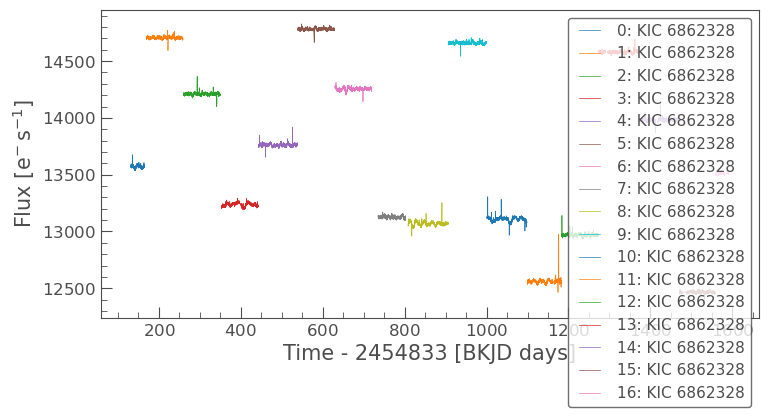

In [7]:
alldata=searchtable.download_all() #download all the light curves (slow but useful since some quarters might not have transit).
alldata.plot() #built-in plot function of lightkurve. It plots all the quarters in one figure, but it is not very flexible.
plt.show() #necessary since it will glitch if not included.

We can see that the flux across quarters are not consistent, even inside the same quarter, it has variations over time.

In [8]:
alldata[0][:10] #showing the structure of the light curve data.

time,flux,flux_err,quality,timecorr,centroid_col,centroid_row,cadenceno,sap_flux,sap_flux_err,sap_bkg,sap_bkg_err,pdcsap_flux,pdcsap_flux_err,sap_quality,psf_centr1,psf_centr1_err,psf_centr2,psf_centr2_err,mom_centr1,mom_centr1_err,mom_centr2,mom_centr2_err,pos_corr1,pos_corr2
,electron / s,electron / s,,d,pix,pix,,electron / s,electron / s,electron / s,electron / s,electron / s,electron / s,,pix,pix,pix,pix,pix,pix,pix,pix,pix,pix
Time,float32,float32,int32,float32,float64,float64,int32,float32,float32,float32,float32,float32,float32,int32,float64,float32,float64,float32,float64,float32,float64,float32,float32,float32
131.51241161194048,1.3572333e+04,4.4652367e+00,0,1.417792e-03,574.86492,447.75327,1105,1.4699763e+04,3.8179066e+00,6.6104492e+02,7.1405523e-02,1.3572333e+04,4.4652367e+00,0,———,———,———,———,574.86492,2.5654843e-04,447.75327,2.7185600e-04,1.2487111e-02,-1.2917025e-02
131.5328461864483,1.3563508e+04,4.4663148e+00,0,1.418666e-03,574.86371,447.75304,1106,1.4692646e+04,3.8174613e+00,6.6081787e+02,7.1310237e-02,1.3563508e+04,4.4663148e+00,0,———,———,———,———,574.86371,2.5650891e-04,447.75304,2.7184543e-04,1.2444285e-02,-1.2944393e-02
131.5532806607298,1.3566247e+04,4.4711843e+00,0,1.419541e-03,574.86490,447.75294,1107,1.4695224e+04,3.8175631e+00,6.5984570e+02,7.1386263e-02,1.3566247e+04,4.4711843e+00,0,———,———,———,———,574.86490,2.5655684e-04,447.75294,2.7187139e-04,1.2296822e-02,-1.2806542e-02
131.57371503500326,1.3568099e+04,4.4668717e+00,10000000000000,1.420415e-03,574.86463,447.75334,1108,1.4696391e+04,3.8177643e+00,6.5999152e+02,7.1329877e-02,1.3568099e+04,4.4668717e+00,10000000000000,———,———,———,———,574.86463,2.5659005e-04,447.75334,2.7191927e-04,1.2088828e-02,-1.2662738e-02
131.59414950916835,1.3567496e+04,4.4701872e+00,0,1.421289e-03,574.86364,447.75221,1109,1.4695645e+04,3.8176153e+00,6.6026508e+02,7.1353607e-02,1.3567496e+04,4.4701872e+00,0,———,———,———,———,574.86364,2.5657023e-04,447.75221,2.7192468e-04,1.2224003e-02,-1.3374834e-02
131.6145840833342,1.3566365e+04,4.4673262e+00,0,1.422163e-03,574.86405,447.75201,1110,1.4694638e+04,3.8175170e+00,6.6020557e+02,7.1391225e-02,1.3566365e+04,4.4673262e+00,0,———,———,———,———,574.86405,2.5653734e-04,447.75201,2.7184087e-04,1.2250951e-02,-1.3307320e-02
131.6350184573821,1.3563201e+04,4.4709496e+00,10000000000000,1.423037e-03,574.86451,447.75268,1111,1.4692190e+04,3.8172526e+00,6.6030219e+02,7.1389548e-02,1.3563201e+04,4.4709496e+00,10000000000000,———,———,———,———,574.86451,2.5655434e-04,447.75268,2.7188958e-04,1.2276179e-02,-1.3221733e-02
131.65545293130708,1.3564596e+04,4.4716997e+00,0,1.423911e-03,574.86450,447.75261,1112,1.4693180e+04,3.8174307e+00,6.6010706e+02,7.1350232e-02,1.3564596e+04,4.4716997e+00,0,———,———,———,———,574.86450,2.5657413e-04,447.75261,2.7186019e-04,1.2464145e-02,-1.3439215e-02


time is in the unit of BKJD which is BJD-2454833 days which is 0 on Jan 1st, 2009 12:00PM UTC, 3 months before Kepler is launched. \
The reason I have to use "sap_flux" (Simple Aperture Photometry) is because it is raw flux. \
"flux" is PDCSAP (Pre-search Data Conditioning SAP), which is processed to remove the background noise and long-term variation.

In [9]:
def hasTransit(data,t0=t0,period=period): #check if the light curve has transit or not. It returns True if it has transit, otherwise False.
    tmin=data.time.value.min() #min time in the quarter.
    tmax=data.time.value.max() #max time in the quarter.
    tlist=data.time.value #list of time
    nmin=int((tmin-t0)//period+1) #min 
    nmax=int((tmax-t0)//period)
    for i in range(nmin,nmax+1):
        tt=t0+i*period #transit time
        if (tt>tmin) and (tt<tmax) and min(abs(tt-tlist))<0.1: #check if transit time is in the quarter and if it is in no data areas.
            return True
    return False

def vlines(data,t0=t0,period=period): #draw vertical lines at the transit times.
    tmin=data.time.value.min()
    tmax=data.time.value.max()
    nmin=int((tmin-t0)//period+1)
    nmax=int((tmax-t0)//period)
    for i in range(nmin,nmax+1):
        plt.axvline(x=t0+i*period,color='r',linestyle='--',linewidth=0.5)

def lcplot(tbl,t0=t0,period=period,id=id,customtxt=None): #built-in plot of lightkurve with some customization.
    tbl.plot(marker='o',markersize=0.5,linewidth=0.3)
    plt.title(kicid(id)+' '+str(customtxt))
    plt.xlabel('Time [BKJD days]')
    plt.ylabel('Flux [e-/s]')
    vlines(tbl,t0,period)

Flatten data plots

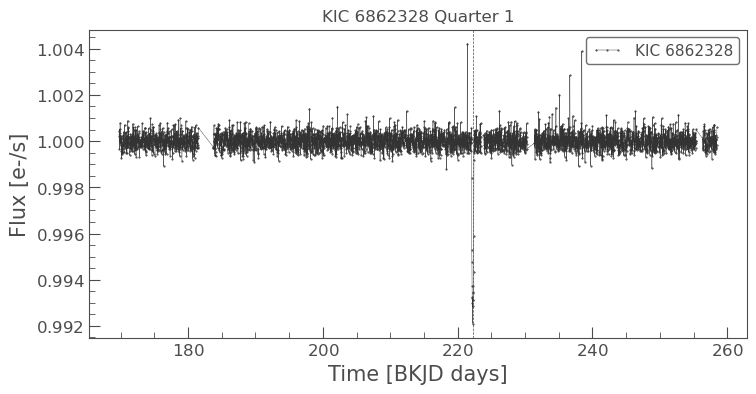

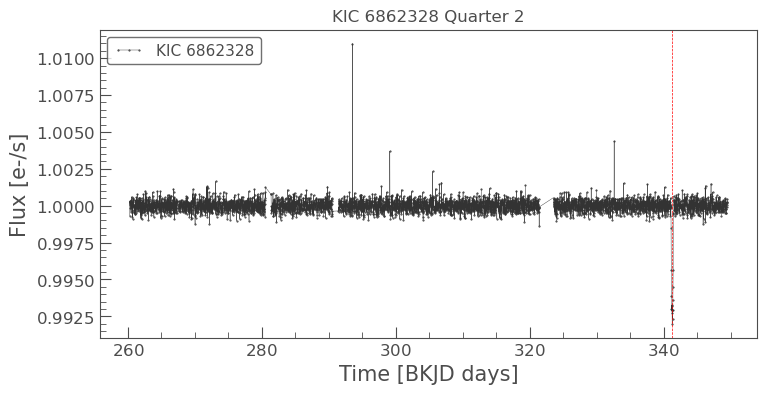

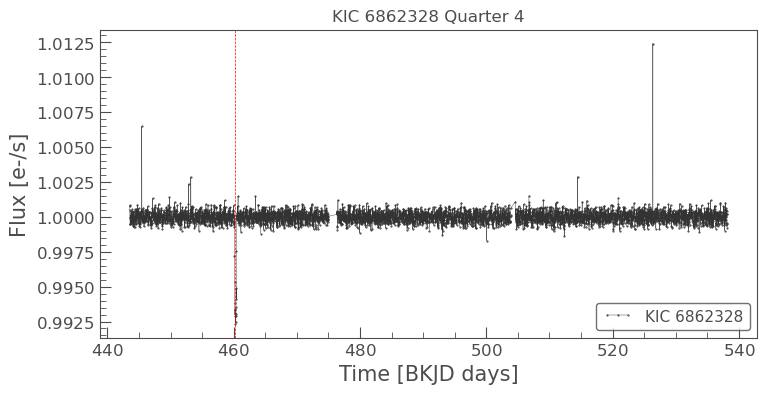

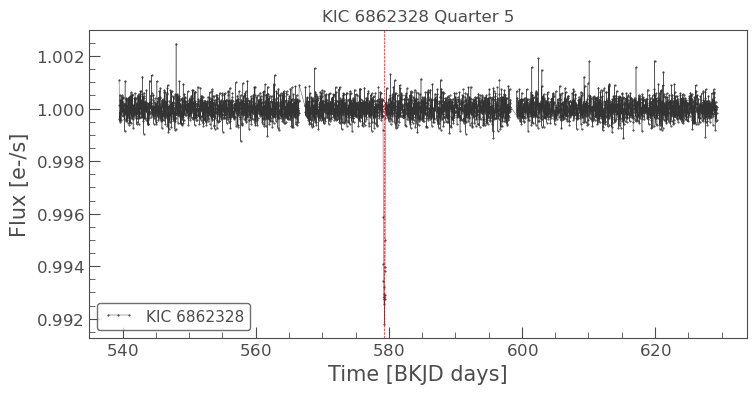

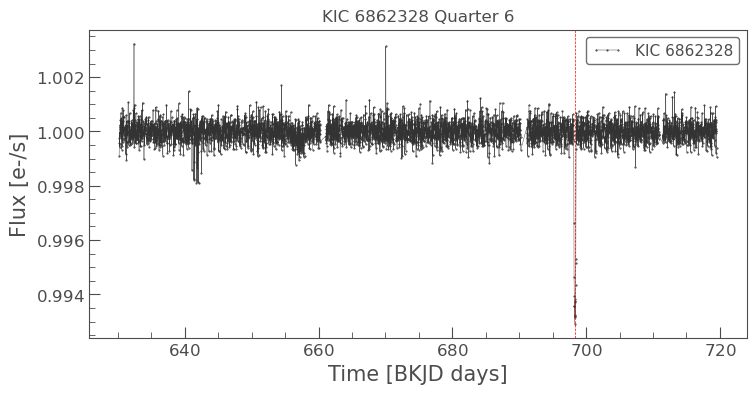

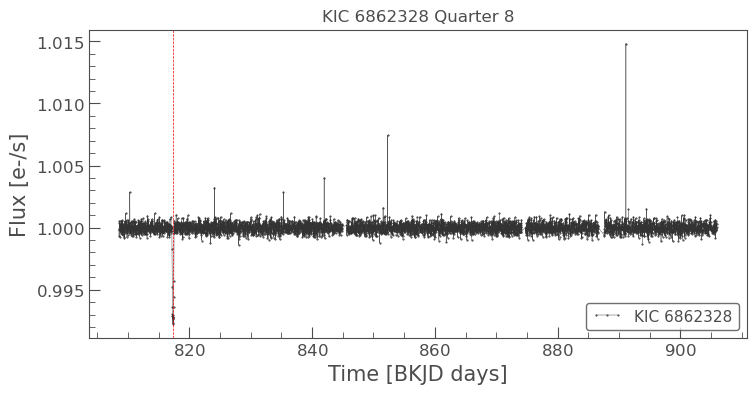

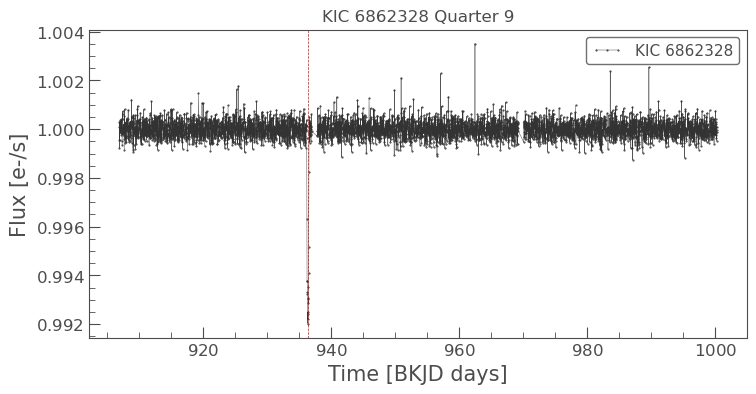

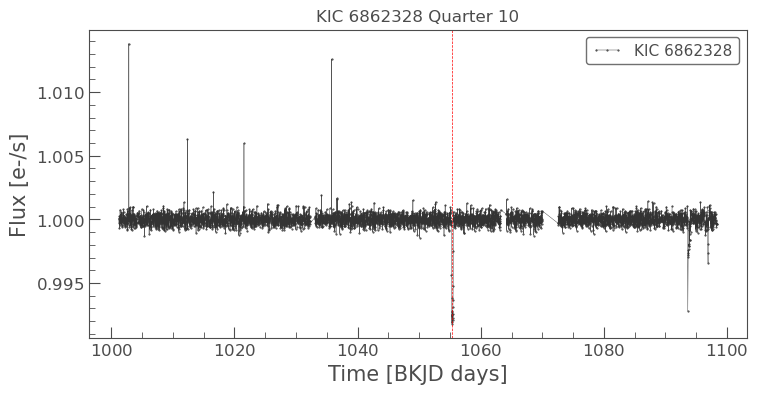

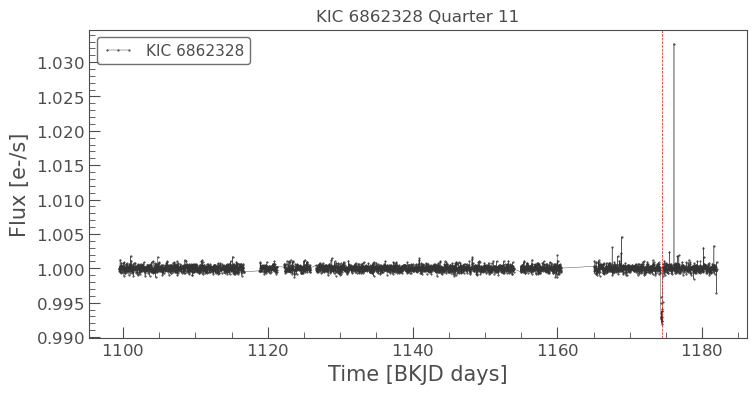

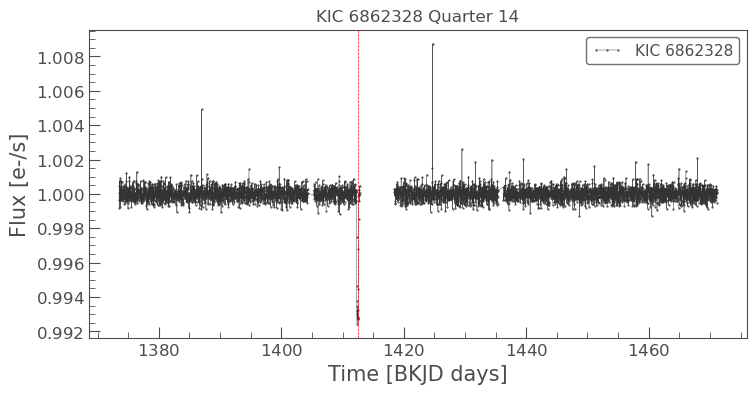

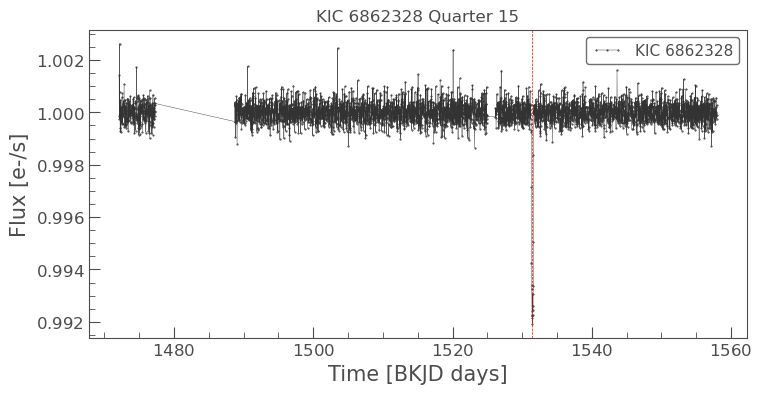

In [10]:
for q in range(len(alldata)): #loop through all the quarters of the light curve data.
    if hasTransit(alldata[q]): #plot only the quarters that have transit.
        flatdata=alldata[q].flatten(window_length=101) #flatten (Savitzky–Golay filter) the light curve to better visualize the transit.
        lcplot(flatdata,customtxt='Quarter '+str(q)) #plot the light curve function.
        plt.show()

Processed data plot

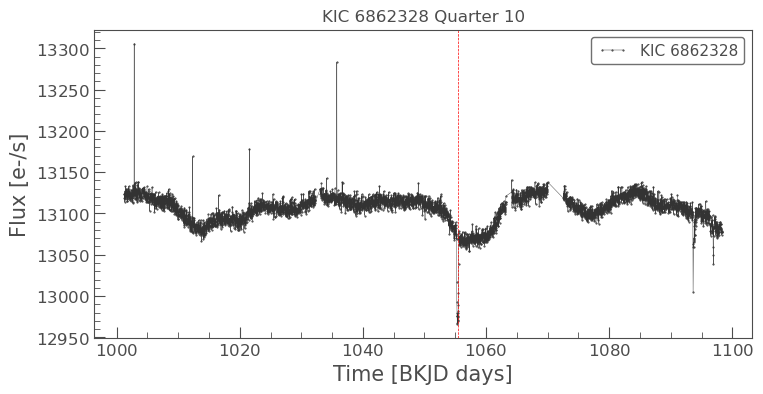

In [11]:
data=alldata[10] #I choose quarter 10 to demonstrate the data since it has transit and an imposter around t = 1093.7 days.
lcplot(data,customtxt='Quarter 10') #plot the processed light curve function.
plt.show()

Raw data plot

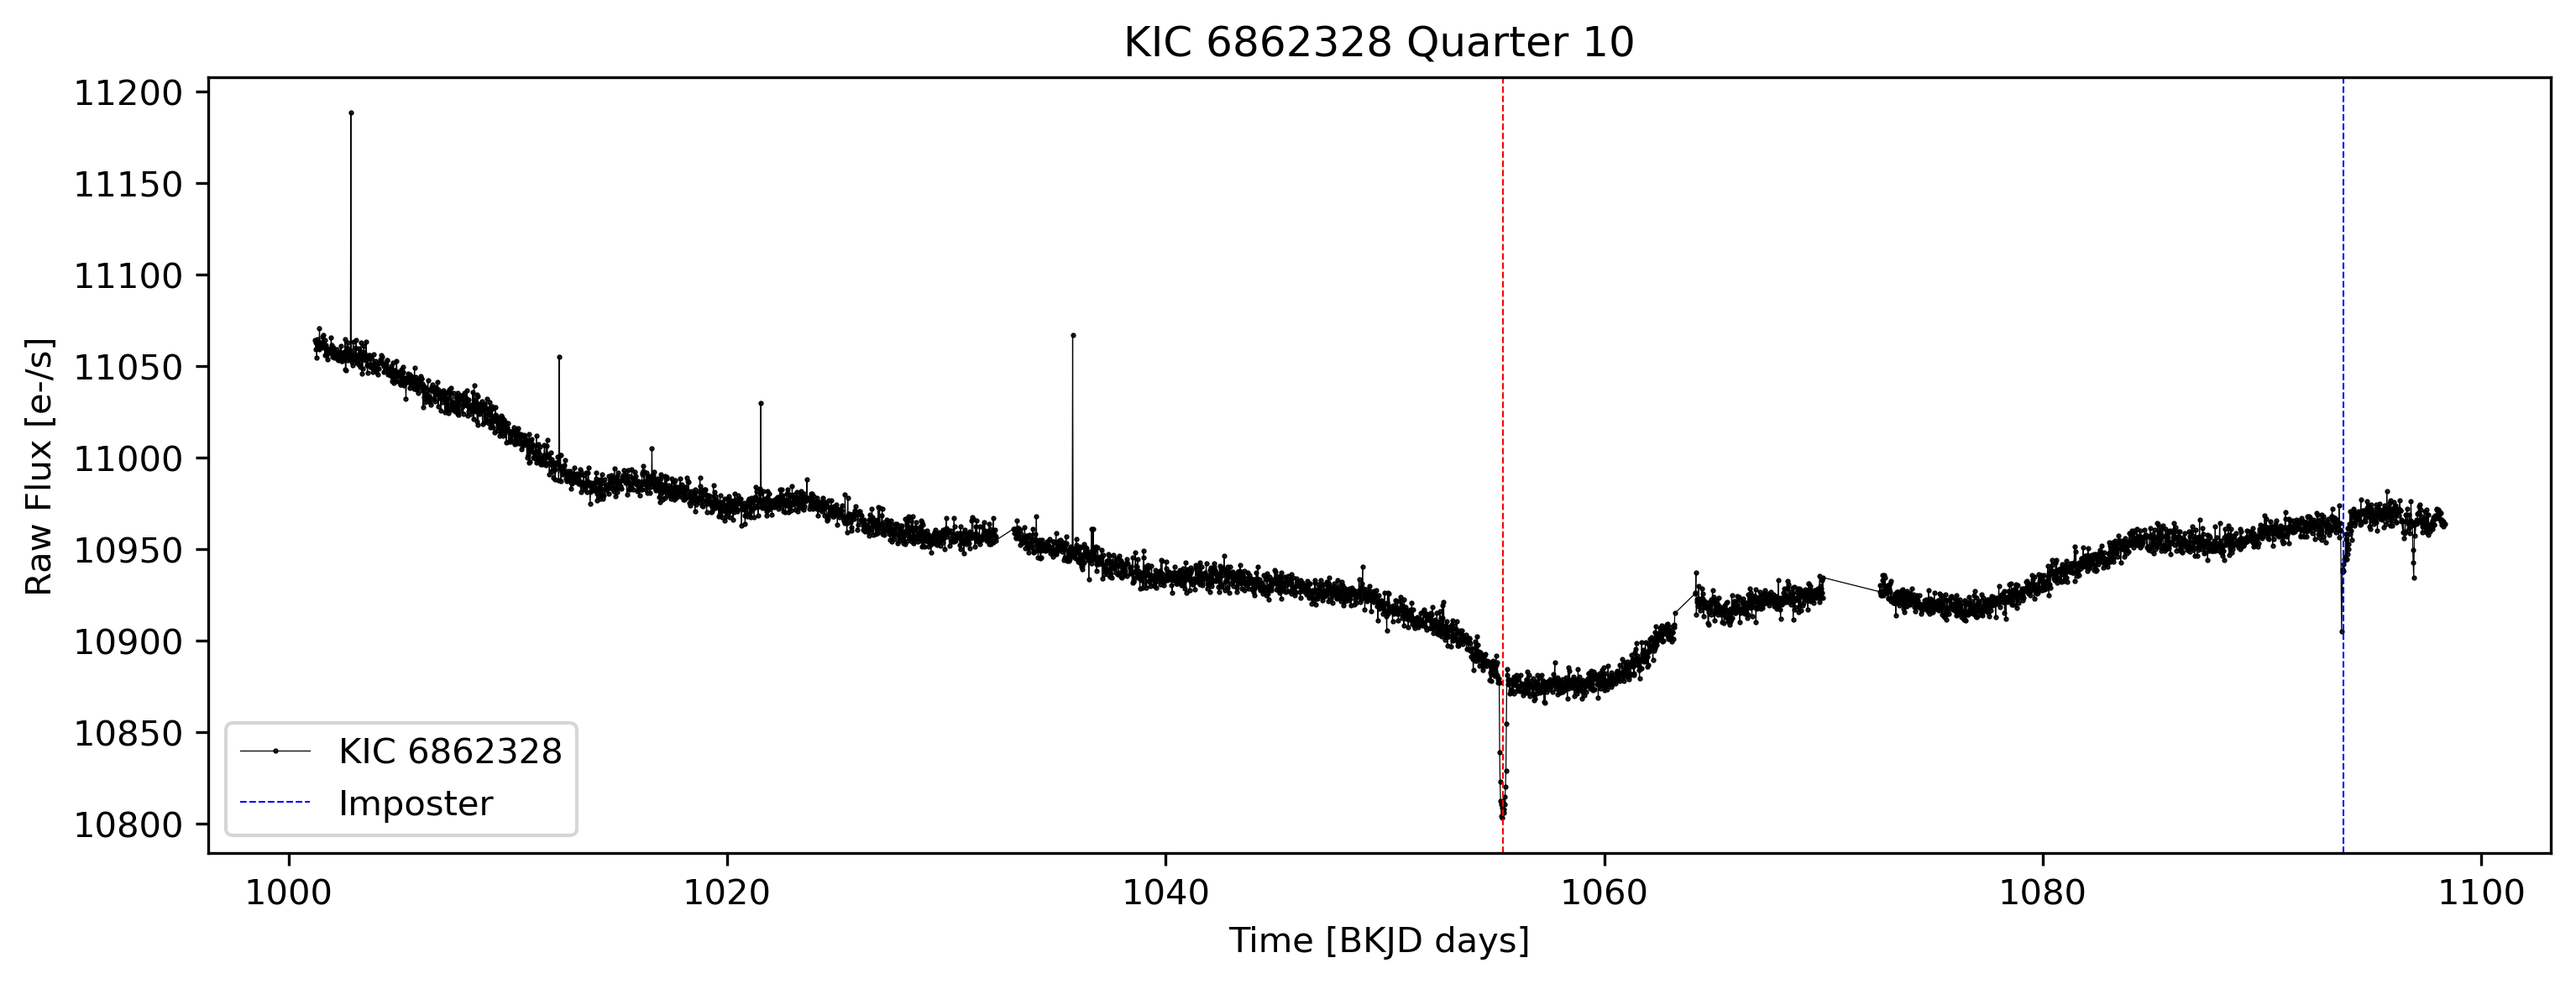

In [12]:
plt.plot(data.time.value,data.sap_flux.value,color='k',marker='o',markersize=0.5,linewidth=0.3,label=kicid(id)) #plot raw data of quarter 10.
plt.title(kicid(id)+' '+str('Quarter 10'))
plt.xlabel('Time [BKJD days]')
plt.ylabel('Raw Flux [e-/s]')
vlines(data,t0,period)
plt.axvline(x=1093.7,color='b',linestyle='--',linewidth=0.5,label='Imposter') #draw a blue vertical line at the imposter.
plt.legend()
plt.show()

We can already see the imposter (blue line) that represents the look-elsewhere effect or it might be another planet. This is what I will do in this project, determining the statistical significance in terms of $\sigma$ of candidate stars that I will choose randomly from the list.